# Application scoring — v1: cave exploration (lava tubes)
## Reads cells.parquet, writes cells_scored.parquet

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from sklearn.neighbors import BallTree
import matplotlib.pyplot as plt

RAW = Path("../data/raw")
OUT = Path("../data/processed")
(RAW / "gvp").mkdir(parents=True, exist_ok=True)

RES, NCOLS, NROWS = 0.5, 720, 360
R_EARTH_KM = 6371.0

def cell_id(lat, lon):
    lat = np.asarray(lat); lon = np.asarray(lon)
    return ((90 - lat) // RES).astype(int) * NCOLS + ((lon + 180) // RES).astype(int)

## Load the master table

In [2]:
cells = pd.read_parquet(OUT / "cells.parquet")
need = ["temp_p", "precip_p", "barren_pct", "passes_all"]
missing = [c for c in need if c not in cells]
if missing:
    raise ValueError(f"Missing columns {missing}: rerun the first notebook with the new WorldClim layers")
print(f"Loaded {len(cells):,} cells, {cells.passes_all.sum():,} pass the discriminator")

Loaded 95,447 cells, 62,626 pass the discriminator


## Download Smithsonian Holocene volcanoes (WFS → CSV)

In [3]:
GVP_CSV = RAW / "gvp" / "holocene_volcanoes.csv"
WFS = "https://webservices.volcano.si.edu/geoserver/GVP-VOTW/wfs"

# --- Download (skipped if the file already exists) ---
if GVP_CSV.exists():
    print(f"✓ already have {GVP_CSV.name}")
else:
    caps = requests.get(WFS, params={"service": "WFS", "request": "GetCapabilities"}, timeout=60).text
    layer_names = re.findall(r"<(?:wfs:)?Name>([^<]+)</(?:wfs:)?Name>", caps)
    holo = [n for n in layer_names if "holocene" in n.lower() and "volcan" in n.lower()]
    print("WFS layers:", layer_names)
    if not holo:
        raise ValueError("No Holocene volcano layer found; pick one from the list above")
    print("Using layer:", holo[0])
    r = requests.get(WFS, params={"service": "WFS", "version": "1.0.0", "request": "GetFeature",
                                  "typeName": holo[0], "outputFormat": "csv"}, timeout=120)
    r.raise_for_status()
    GVP_CSV.write_bytes(r.content)
    print(f"✓ downloaded {GVP_CSV.name}")

# --- Sanity check: did the server return data or an error? ---
head = GVP_CSV.read_text(errors="ignore")[:500]
if head.lstrip().startswith("<"):
    GVP_CSV.unlink()                      # delete the bad file so the next run re-downloads
    raise ValueError("WFS returned XML (an error), not CSV:\n" + head)

volc = pd.read_csv(GVP_CSV)
print("Volcano columns:", volc.columns.tolist())
print(volc.head(3).T)                     # look at the first rows

# --- Coordinates: fuzzy column match ---
def find_col(keys):
    for c in volc.columns:
        cl = c.lower()
        if any(k in cl for k in keys):
            return c
    return None

lat_c = find_col(["latitude", "lat"])
lon_c = find_col(["longitude", "lon", "long"])
geom_c = find_col(["geom", "shape", "wkt", "location"])

if lat_c and lon_c:
    volc["lat"] = pd.to_numeric(volc[lat_c], errors="coerce")
    volc["lon"] = pd.to_numeric(volc[lon_c], errors="coerce")
elif geom_c:
    xy = volc[geom_c].astype(str).str.extract(r"POINT\s*\(\s*([-\d.]+)\s+([-\d.]+)")
    volc["lon"], volc["lat"] = xy[0].astype(float), xy[1].astype(float)
else:
    raise ValueError("No coordinate columns found; see the column list printed above")

volc = volc.dropna(subset=["lat", "lon"])
print(f"Volcanoes with coordinates: {len(volc):,}")

# --- Basaltic volcanoes (lava tubes form in basalt) ---
# The WFS CSV has no rock-type column, so use VolcanoType as a proxy:
# shields, volcanic fields, fissure vents and lava cones are mostly effusive basalt,
# while stratovolcanoes, calderas and lava domes are mostly andesitic/explosive.
BASALTIC_TYPES = r"shield|volcanic field|fissure|lava cone|lava field|pyroclastic cone"
type_c = next((c for c in volc.columns if c.lower() == "volcanotype"), None)
if type_c:
    volc["basaltic"] = volc[type_c].astype(str).str.contains(BASALTIC_TYPES, case=False, regex=True)
    print("Volcano types counted as basaltic:")
    print(volc.loc[volc.basaltic, type_c].value_counts().to_string())
else:
    volc["basaltic"] = True
    print("⚠ No VolcanoType column found; using all volcanoes")
print(f"Volcanoes: {len(volc):,} total, {volc.basaltic.sum():,} basaltic")


✓ already have holocene_volcanoes.csv
Volcano columns: ['FID', 'VolcanoNumber', 'VolcanoName', 'Country', 'Remarks', 'VolcanoType', 'LastEruption', 'Elevation', 'TectonicSetting', 'Within_5km', 'Within_10km', 'Within_30km', 'Within_100km', 'VPImageFileName', 'VPImageCaption', 'VPImageCredit', 'LatitudeDecimal', 'LongitudeDecimal', 'GeoLocation']
                                                                  0  \
FID               E3WebApp_HoloceneVolcanoes.fid-bc1c4cb_1a1e009...   
VolcanoNumber                                                210010   
VolcanoName                               West Eifel Volcanic Field   
Country                                                     Germany   
Remarks           The West Eifel Volcanic Field of western Germa...   
VolcanoType                                          Volcanic field   
LastEruption                                                -8300.0   
Elevation                                                     600.0   
TectonicSetti

## Distance from each cell to the nearest basaltic volcano 

In [4]:
def nearest_km(df, pts):
    tree = BallTree(np.radians(pts[["lat", "lon"]].to_numpy()), metric="haversine")
    d, _ = tree.query(np.radians(df[["lat", "lon"]].to_numpy()), k=1)
    return d[:, 0] * R_EARTH_KM

cells["dist_basalt_volc_km"] = nearest_km(cells, volc[volc.basaltic])
# 1.0 within 25 km (≈ volcano in the cell), linear down to 0 at 100 km
cells["volc_prox"] = np.clip(1 - (cells.dist_basalt_volc_km - 25) / 75, 0, 1)
cells["barren"] = cells.barren_pct.fillna(0) / 100

## Scoring

In [5]:
def score(df, spec, gate):
    cols = list(spec["target"])
    w = np.array([spec["weights"][c] for c in cols], dtype=float)
    X = df[cols].to_numpy(dtype=float)
    t = np.array([spec["target"][c] for c in cols], dtype=float)
    dirs = [spec.get("dir", {}).get(c, "eq") for c in cols]

    diff = X - t
    for j, dname in enumerate(dirs):
        if dname == "max":              # only too high is bad
            diff[:, j] = np.maximum(diff[:, j], 0)
        elif dname == "min":            # only too low is bad
            diff[:, j] = np.minimum(diff[:, j], 0)

    valid = ~np.isnan(X)
    d = np.sqrt(np.nansum(w * diff ** 2, axis=1) / (valid * w).sum(axis=1))
    return np.where(gate, 1 - d, 0.0)

# --- Gate: discriminator + basaltic volcano within 100 km ---
# Water is ignored for caves: nearby ocean doesn't affect a lava tube underground
# (keeps island sites like Lanzarote). Switch to cells.passes_all for the strict version.
GATE_KM = 100
cave_gate = (cells.pass_forest & cells.pass_urban
             & (cells.dist_basalt_volc_km <= GATE_KM))

CAVE = {
    "moon": {"target":  {"volc_prox": 1.0,   "precip_p": 0.20,  "barren": 1.0},
             "weights": {"volc_prox": 3,     "precip_p": 1,     "barren": 0.5},
             "dir":     {"volc_prox": "min", "precip_p": "max", "barren": "min"}},
    "mars": {"target":  {"volc_prox": 1.0,   "precip_p": 0.20,  "temp_p": 0.10,  "barren": 1.0},
             "weights": {"volc_prox": 3,     "precip_p": 1,     "temp_p": 2,     "barren": 0.5},
             "dir":     {"volc_prox": "min", "precip_p": "max", "temp_p": "max", "barren": "min"}},
}
for body, spec in CAVE.items():
    cells[f"score_cave_{body}"] = score(cells, spec, cave_gate)

# --- 1. Suitability: is this a cave site? ---
CAVE_KM = 50                                   # basaltic volcano in or next to the cell
is_cave_site = cave_gate & (cells.dist_basalt_volc_km <= CAVE_KM)

# --- 2. Body: Moon vs Mars, with a tie zone ---
moon, mars = cells.score_cave_moon, cells.score_cave_mars
MARGIN = 0.03
body = np.where((moon - mars).abs() < MARGIN, "both",
                np.where(moon > mars, "moon", "mars"))

cells["label_cave"] = np.where(is_cave_site, body, "")

# --- 3. Quality: for ranking within the label only ---
cells["cave_quality"] = np.where(is_cave_site, np.maximum(moon, mars), 0.0)

print(f"Cave gate passed: {cave_gate.sum():,} cells")
print(f"Cave sites (basaltic volcano ≤ {CAVE_KM} km): {is_cave_site.sum():,} cells")
print("Cave labels:", cells.label_cave.replace("", "none").value_counts().to_dict())

print("\nTop 10 cave cells:")
display(cells[is_cave_site].nlargest(10, "cave_quality")
        [["cell_id", "lat", "lon", "dist_basalt_volc_km", "precip_p", "temp_p",
          "barren", "score_cave_moon", "score_cave_mars", "label_cave"]].round(2))

Cave gate passed: 1,732 cells
Cave sites (basaltic volcano ≤ 50 km): 585 cells
Cave labels: {'none': 94862, 'moon': 330, 'both': 197, 'mars': 58}

Top 10 cave cells:


,cell_id,lat,lon,dist_basalt_volc_km,precip_p,temp_p,barren,score_cave_moon,score_cave_mars,label_cave
45393,95411,23.75,5.75,20.58,0.15,0.77,1.00,1.00,0.63,moon
45684,96131,23.25,5.75,12.08,0.20,0.73,1.00,1.00,0.65,moon
46875,99032,21.25,16.25,12.16,0.20,0.80,1.00,1.00,0.61,moon
65296,164382,-24.25,-68.75,17.94,0.08,0.64,1.00,1.00,0.70,moon
48480,103385,18.25,32.75,8.90,0.11,0.99,1.00,1.00,0.51,moon
47670,101197,19.75,18.75,23.68,0.15,0.80,1.00,1.00,0.61,moon
65659,165823,-25.25,-68.25,19.19,0.16,0.57,1.00,1.00,0.74,moon
44567,93315,25.25,37.75,8.90,0.19,0.83,1.00,1.00,0.59,moon
40067,83235,32.25,37.75,18.21,0.20,0.74,0.98,0.99,0.65,moon
46041,96922,22.75,41.25,14.44,0.23,0.98,1.00,0.99,0.51,moon


## Validation

In [6]:
sites = pd.DataFrame([
    ("Craters of the Moon, Idaho",  43.42, -113.52),
    ("Lava Beds, California",       41.71, -121.51),
    ("Mauna Loa (HI-SEAS), Hawaii", 19.60, -155.47),
    ("Cueva de los Verdes, Lanzarote", 29.16, -13.44),
    ("Undara, Australia",          -18.20,  144.60),
    ("Raufarhólshellir, Iceland",   64.02,  -21.40),
], columns=["name", "lat", "lon"])
sites["cell_id"] = cell_id(sites.lat, sites.lon)

cols = ["cell_id", "dist_basalt_volc_km", "volc_prox", "precip_p", "temp_p", "barren",
        "score_cave_moon", "score_cave_mars", "cave_quality", "label_cave", "passes_all", "excluded_by"]
check = sites.merge(cells[cols], on="cell_id", how="left")
check["excluded_by"] = check["excluded_by"].fillna("not a land cell")
print("\nKnown lava-tube sites:")
display(check.drop(columns=["cell_id", "lat", "lon"]).round(2))


Known lava-tube sites:


,name,dist_basalt_volc_km,volc_prox,precip_p,temp_p,barren,score_cave_moon,score_cave_mars,cave_quality,label_cave,passes_all,excluded_by
0,"Craters of the Moon, Idaho",24.77,1.00,0.48,0.60,0.04,0.65,0.60,0.65,moon,True,
1,"Lava Beds, California",22.45,1.00,0.60,0.61,0.01,0.62,0.58,0.62,moon,True,
2,"Mauna Loa (HI-SEAS), Hawaii",24.30,1.00,0.95,0.71,0.12,0.00,0.00,0.00,,False,forest
3,"Cueva de los Verdes, Lanzarote",44.28,0.74,0.29,0.75,0.02,0.61,0.52,0.61,moon,False,water
4,"Undara, Australia",23.29,1.00,0.77,0.78,0.00,0.57,0.48,0.57,moon,True,
5,"Raufarhólshellir, Iceland",28.48,0.95,0.85,0.55,0.03,0.55,0.55,0.55,both,True,


## Maps

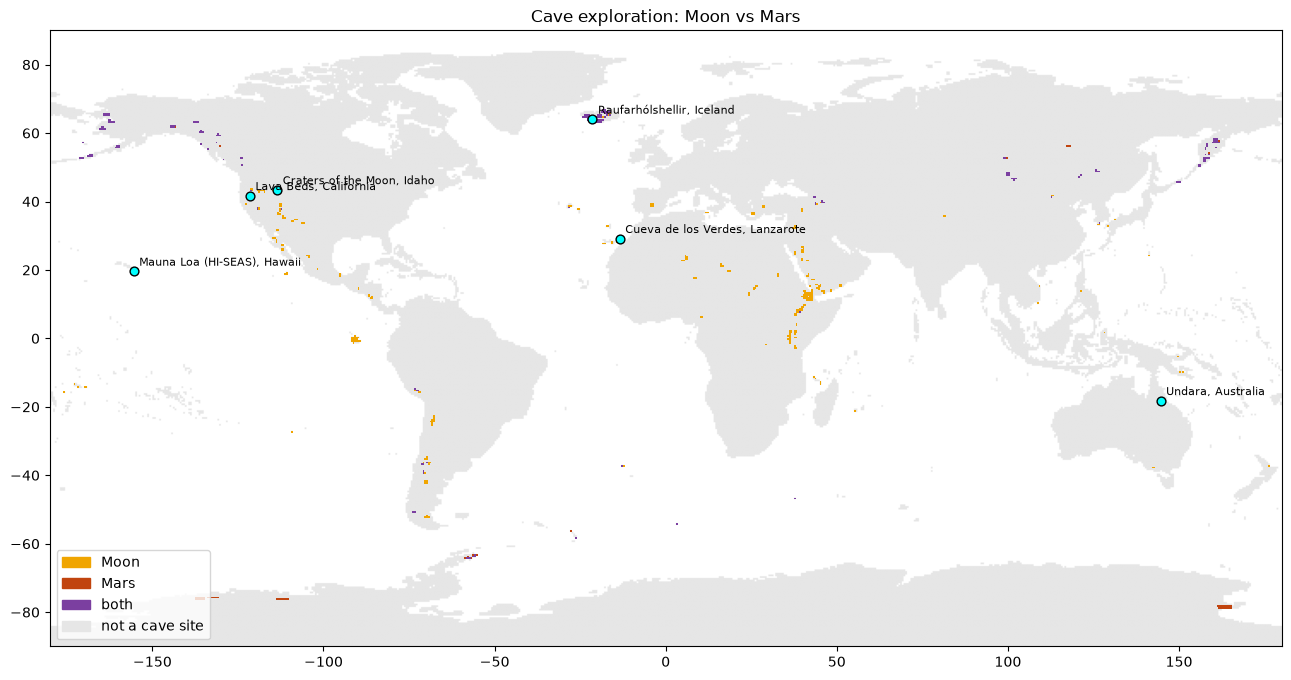

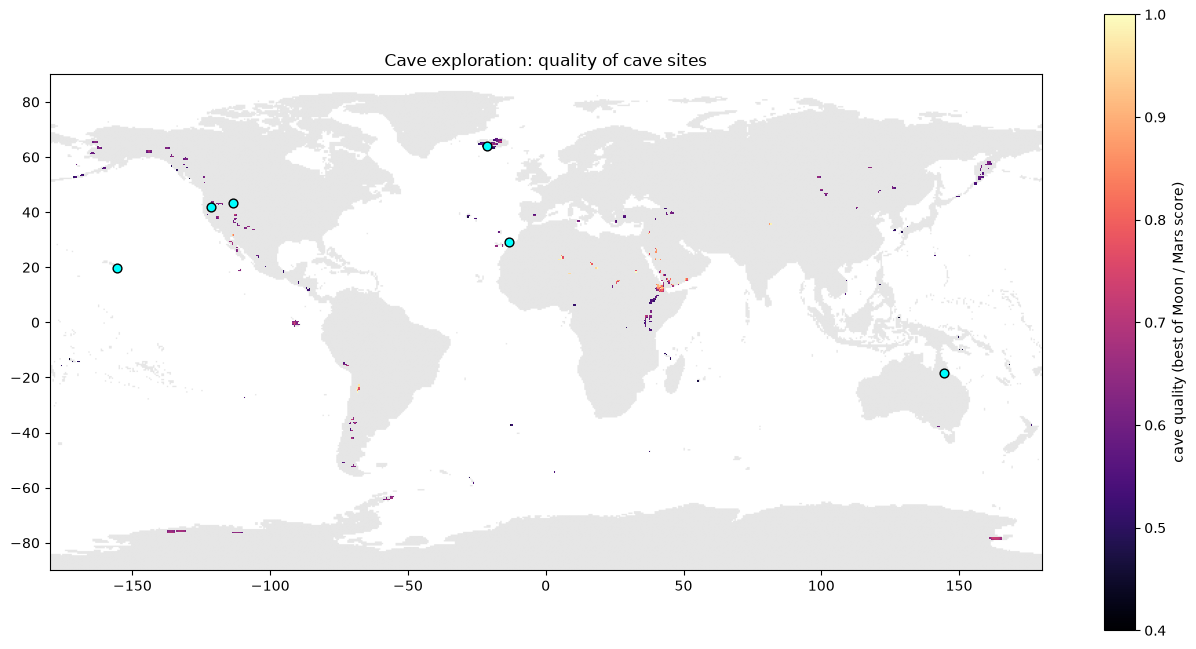

In [7]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

def to_grid(values):
    grid = np.full((NROWS, NCOLS), np.nan)
    r, c = np.divmod(cells.cell_id.values, NCOLS)
    grid[r, c] = values
    return grid

# Background: all land cells, light grey
land = to_grid(np.ones(len(cells)))

# Map 1: cave labels
code = cells.label_cave.map({"moon": 1, "mars": 2, "both": 3}).fillna(0).values
lab = to_grid(code)
lab[lab == 0] = np.nan

colors = {1: "#f0a500", 2: "#c1440e", 3: "#7b3fa0"}     # moon / mars / both
fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(land, extent=[-180, 180, -90, 90], cmap=ListedColormap(["#e6e6e6"]))
ax.imshow(lab, extent=[-180, 180, -90, 90],
          cmap=ListedColormap([colors[1], colors[2], colors[3]]), vmin=1, vmax=3,
          interpolation="nearest")
ax.scatter(sites.lon, sites.lat, c="cyan", s=40, edgecolor="k", zorder=3)
for _, s in sites.iterrows():
    ax.annotate(s["name"], (s.lon, s.lat), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.legend(handles=[Patch(color=colors[1], label="Moon"),
                   Patch(color=colors[2], label="Mars"),
                   Patch(color=colors[3], label="both"),
                   Patch(color="#e6e6e6", label="not a cave site")], loc="lower left")
ax.set_title("Cave exploration: Moon vs Mars")
plt.show()

# Map 2: cave quality (ranking score within cave sites)
q = to_grid(cells.cave_quality.values)
q[q == 0] = np.nan

fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(land, extent=[-180, 180, -90, 90], cmap=ListedColormap(["#e6e6e6"]))
im = ax.imshow(q, extent=[-180, 180, -90, 90], cmap="magma", vmin=0.4, vmax=1,
               interpolation="nearest")
plt.colorbar(im, ax=ax, label="cave quality (best of Moon / Mars score)")
ax.scatter(sites.lon, sites.lat, c="cyan", s=40, edgecolor="k", zorder=3)
ax.set_title("Cave exploration: quality of cave sites")
plt.show()

## Save (base table stays untouched)

In [8]:
cells.to_parquet(OUT / "cells_scored.parquet", index=False)
print(f"Saved {OUT / 'cells_scored.parquet'}")

Saved ../data/processed/cells_scored.parquet
